# 🤖 Tarea 1 – Parte 2: Del LLM al clasificador

**Pregunta guía:** ¿Pueden convertir titulares peruanos en un clasificador de noticias?

**Datos:** `datos/noticias.csv`, generado en `01_recoleccion.ipynb` (El Comercio, 4 categorías).

**Flujo de este notebook**
1. **Línea base zero-shot:** se evalúa un modelo NLI sin entrenamiento en 40 titulares.
2. **Supervisión débil con LLM:** Gemini etiqueta todo el dataset y se hace una auditoría humana de 20 casos.
3. **Split 70/15/15** estratificado con `random_state=42`.
4. **Fine-tuning** de DistilBERT multilingüe con las etiquetas del LLM.
5. **Evaluación final** en el test reservado: accuracy, F1 macro y matriz de confusión.
6. **Comparativa y decisión** entre los tres enfoques.

**Etiqueta de referencia (*gold*):** la columna `etiqueta` del CSV, que proviene de la sección editorial donde El Comercio publicó la noticia. Todas las métricas finales se calculan contra ella en el **conjunto de test**.

## 0. Configuración

In [1]:
import os, re, json, time, random
from datetime import datetime

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from transformers import (pipeline, AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding, set_seed)

SEMILLA = 42
set_seed(SEMILLA); random.seed(SEMILLA); np.random.seed(SEMILLA)

CATEGORIAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]
label2id = {c: i for i, c in enumerate(CATEGORIAS)}
id2label = {i: c for c, i in label2id.items()}

DISPOSITIVO = 0 if torch.cuda.is_available() else -1      # 0 = GPU, -1 = CPU
os.makedirs("modelo", exist_ok=True)

df = pd.read_csv("datos/noticias.csv").fillna("")
print("Dataset:", df.shape, "| GPU disponible:", torch.cuda.is_available())
df["etiqueta"].value_counts()

Dataset: (388, 7) | GPU disponible: False


etiqueta
deportes              100
economia               99
ciencia_tecnologia     95
politica               94
Name: count, dtype: int64

## 1. Línea base zero-shot (sin fine-tuning)
Se usa `Recognai/bert-base-spanish-wwm-cased-xnli`, un modelo NLI entrenado en español. Clasifica sin haber visto ningún ejemplo de nuestro dataset: solo compara cada titular con la frase *"Esta noticia trata sobre {categoría}"*.

Se evalúan **40 titulares** (10 por categoría, muestra aleatoria con semilla fija). Este puntaje es el **piso mínimo a superar**.

In [2]:
MODELO_ZS = "Recognai/bert-base-spanish-wwm-cased-xnli"
clasificador_zs = pipeline("zero-shot-classification", model=MODELO_ZS, device=DISPOSITIVO)

# Etiquetas en lenguaje natural (el modelo entiende mejor "ciencia y tecnología" que "ciencia_tecnologia")
ETIQUETAS_ZS = {"política": "politica", "economía": "economia",
                "deportes": "deportes", "ciencia y tecnología": "ciencia_tecnologia"}
PLANTILLA_ZS = "Esta noticia trata sobre {}."

def predecir_zero_shot(titulares):
    salidas = clasificador_zs(list(titulares), candidate_labels=list(ETIQUETAS_ZS),
                              hypothesis_template=PLANTILLA_ZS)
    return [ETIQUETAS_ZS[s["labels"][0]] for s in salidas]

muestra_zs = df.groupby("etiqueta").sample(10, random_state=SEMILLA).copy()
muestra_zs["pred_zero_shot"] = predecir_zero_shot(muestra_zs["titular"])

acc_zs40 = accuracy_score(muestra_zs["etiqueta"], muestra_zs["pred_zero_shot"])
f1_zs40  = f1_score(muestra_zs["etiqueta"], muestra_zs["pred_zero_shot"], average="macro")
print(f"Zero-shot en 40 titulares → Accuracy: {acc_zs40:.3f} | F1 macro: {f1_zs40:.3f}")
print(classification_report(muestra_zs["etiqueta"], muestra_zs["pred_zero_shot"], zero_division=0))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Zero-shot en 40 titulares → Accuracy: 0.600 | F1 macro: 0.561
                    precision    recall  f1-score   support

ciencia_tecnologia       1.00      0.30      0.46        10
          deportes       0.57      0.80      0.67        10
          economia       0.60      0.30      0.40        10
          politica       0.56      1.00      0.71        10

          accuracy                           0.60        40
         macro avg       0.68      0.60      0.56        40
      weighted avg       0.68      0.60      0.56        40



In [3]:
errores_zs = muestra_zs[muestra_zs["etiqueta"] != muestra_zs["pred_zero_shot"]]
print(f"Errores del zero-shot: {len(errores_zs)} de 40")
errores_zs[["titular", "etiqueta", "pred_zero_shot"]]

Errores del zero-shot: 16 de 40


,titular,etiqueta,pred_zero_shot
68,Fenómeno El Niño Costero: ¿cuáles pueden ser l...,ciencia_tecnologia,deportes
72,Malaria y dengue: el cambio climático influye ...,ciencia_tecnologia,deportes
73,Ventas de ‘smartphones’ registran una caída de...,ciencia_tecnologia,economia
0,¿Cómo lograr que una marca aparezca en ChatGPT...,ciencia_tecnologia,deportes
40,Así es Midnight Mimosa: el ‘malware’ preinstal...,ciencia_tecnologia,economia
42,Microsoft y Nvidia impulsan una nueva categorí...,ciencia_tecnologia,deportes
10,Organización que gestiona Wikipedia denuncia a...,ciencia_tecnologia,deportes
112,“Estaba en el banquillo hablando con Dios”: En...,deportes,politica
110,Amistosos ante Bolivia y Honduras: ¿Por qué de...,deportes,politica
279,"De consultar saldos a delegar operaciones, ¿có...",economia,politica


## 2. Supervisión débil con LLM (Gemini)
Un LLM etiqueta **todo el dataset** con un prompt estructurado: definición de cada categoría, salida JSON obligatoria y un nivel de confianza. Se envían **lotes de 20 titulares por solicitud**, con pausas para respetar el límite gratuito de la API.

**Clave de API:** se lee del archivo `.env` (`GEMINI_API_KEY=...`), que está en `.gitignore` y **nunca se sube a GitHub**.

Si `datos/etiquetas_llm.csv` ya existe, se reutiliza en lugar de volver a llamar a la API. Así el notebook se puede re-ejecutar sin gastar cuota. Además, el avance se guarda **en cada lote**: si se corta, al volver a ejecutar continúa donde quedó.

In [4]:
from dotenv import load_dotenv
from getpass import getpass

load_dotenv(override=True)                     # lee GEMINI_API_KEY del archivo .env

USAR_OLLAMA  = False                           # True para usar un modelo local con Ollama
MODELO_LLM   = "qwen2.5:7b" if USAR_OLLAMA else "gemini-flash-latest"   # siempre el Flash más reciente
TAMANO_LOTE  = 20                              # titulares por solicitud
PAUSA_LLM    = 0 if USAR_OLLAMA else 13        # segundos entre solicitudes (≈ 4–5 por minuto)
RUTA_LLM     = "datos/etiquetas_llm.csv"
RUTA_PARCIAL = "datos/etiquetas_llm_parcial.csv"   # avance guardado lote a lote

PROMPT_SISTEMA = """Eres un editor de un diario peruano. Clasifica cada noticia en UNA de estas 4 categorías:
- politica: Gobierno, Congreso, partidos, elecciones, Poder Judicial, Fiscalía y política internacional.
- economia: mercados, empresas, finanzas, empleo, impuestos, precios, comercio, minería como actividad económica.
- deportes: fútbol, vóley, tenis, automovilismo, running y cualquier competencia o deportista.
- ciencia_tecnologia: ciencia, tecnología, internet, apps, inteligencia artificial, videojuegos, espacio, descubrimientos científicos.
Responde SOLO con una lista JSON, en el mismo orden, con objetos de la forma:
{"id": <número>, "etiqueta": "<categoría>", "confianza": <número entre 0 y 1>}"""

# ── Cliente de Gemini: se crea UNA sola vez y SOLO si hay que etiquetar ────
# Si datos/etiquetas_llm.csv ya existe, nunca se pide la clave (por ejemplo, cuando el profesor ejecuta el notebook).
cliente = None

def obtener_cliente():
    global cliente
    if cliente is None:
        from google import genai
        if not os.environ.get("GEMINI_API_KEY"):
            os.environ["GEMINI_API_KEY"] = getpass("Ingresa tu GEMINI_API_KEY: ").strip()
        cliente = genai.Client(api_key=os.environ["GEMINI_API_KEY"])
    return cliente

def armar_mensaje(lote):
    lineas = [f"{i}. Titular: {r.titular} | Bajada: {r.bajada[:200]}" for i, r in enumerate(lote.itertuples())]
    return "Clasifica estas noticias:\n" + "\n".join(lineas)

def llamar_gemini(mensaje):
    from google.genai import types
    resp = obtener_cliente().models.generate_content(
        model=MODELO_LLM,
        contents=mensaje,                                  # mensaje del usuario: los titulares
        config=types.GenerateContentConfig(
            system_instruction=PROMPT_SISTEMA,             # instrucciones fijas del sistema
            temperature=0,                                 # respuestas deterministas
            response_mime_type="application/json",         # obliga a responder en JSON
        ),
    )
    return resp.text

def llamar_ollama(mensaje):
    import requests
    r = requests.post("http://localhost:11434/api/generate", timeout=300,
                      json={"model": MODELO_LLM, "system": PROMPT_SISTEMA, "prompt": mensaje,
                            "format": "json", "stream": False, "options": {"temperature": 0}})
    return r.json()["response"]

def etiquetar_lote(lote, intentos=3):
    """Devuelve una lista de (etiqueta, confianza) del mismo largo que el lote, o None si falla."""
    for intento in range(intentos):
        try:
            texto = (llamar_ollama if USAR_OLLAMA else llamar_gemini)(armar_mensaje(lote))
            datos = json.loads(re.sub(r"```(json)?", "", texto).strip())
            if isinstance(datos, dict):                    # algunos modelos envuelven la lista
                datos = next(v for v in datos.values() if isinstance(v, list))
            por_id = {int(d["id"]): d for d in datos}
            salida = []
            for i in range(len(lote)):
                d = por_id.get(i, {})
                et = str(d.get("etiqueta", "")).strip().lower()
                salida.append((et if et in CATEGORIAS else "invalido", float(d.get("confianza", 0))))
            return salida
        except Exception as e:
            espera = 30 * (intento + 1)
            print(f"   ⚠️ {type(e).__name__}: {str(e)[:120]} → reintento en {espera} s")
            time.sleep(espera)
    return None

In [5]:
if os.path.exists(RUTA_LLM):
    etiquetas_llm = pd.read_csv(RUTA_LLM)
    print(f"✔ Se reutiliza {RUTA_LLM} ({len(etiquetas_llm)} filas). Bórralo si quieres re-etiquetar.")
else:
    # Retoma el avance si una ejecución anterior se cortó
    hechos = pd.read_csv(RUTA_PARCIAL) if os.path.exists(RUTA_PARCIAL) else pd.DataFrame()
    if len(hechos):
        print(f"↻ Continuando desde la fila {len(hechos)} (avance guardado en {RUTA_PARCIAL})")

    for ini in range(len(hechos), len(df), TAMANO_LOTE):
        lote = df.iloc[ini:ini + TAMANO_LOTE]
        t0 = time.time()
        res = etiquetar_lote(lote)
        if res is None:
            print("⛔ El lote falló 3 veces (¿límite diario de la API?). "
                  "El avance está guardado: vuelve a ejecutar esta celda más tarde.")
            break
        seg = (time.time() - t0) / len(lote)               # latencia real, sin contar las pausas
        nuevo = pd.DataFrame({
            "titular":      lote["titular"].values,
            "etiqueta_llm": [r[0] for r in res],
            "confianza":    [round(r[1], 3) for r in res],
            "modelo_llm":   MODELO_LLM,
            "fecha":        datetime.now().strftime("%Y-%m-%d"),
            "seg_por_titular": seg,
        })
        hechos = pd.concat([hechos, nuevo], ignore_index=True)
        hechos.to_csv(RUTA_PARCIAL, index=False, encoding="utf-8")   # guarda en cada lote
        print(f"  {len(hechos)}/{len(df)} etiquetados")
        time.sleep(PAUSA_LLM)

    if len(hechos) == len(df):
        with open("datos/llm_meta.json", "w") as f:
            json.dump({"modelo_llm": MODELO_LLM, "tamano_lote": TAMANO_LOTE,
                       "seg_por_titular": float(hechos["seg_por_titular"].mean())}, f, indent=2)
        etiquetas_llm = hechos.drop(columns="seg_por_titular")
        etiquetas_llm.to_csv(RUTA_LLM, index=False, encoding="utf-8")
        os.remove(RUTA_PARCIAL)
        print(f"✔ Guardado {RUTA_LLM}")
    else:
        raise RuntimeError("Etiquetado incompleto: vuelve a ejecutar esta celda para continuar.")

assert len(etiquetas_llm) == len(df) and (etiquetas_llm["titular"] == df["titular"]).all(), \
    "etiquetas_llm.csv no corresponde a noticias.csv: bórralo y vuelve a ejecutar"
df["etiqueta_llm"] = etiquetas_llm["etiqueta_llm"].values
df["confianza_llm"] = etiquetas_llm["confianza"].values

print("\nDistribución de etiquetas del LLM:")
print(df["etiqueta_llm"].value_counts().to_string())
print(f"\nConcordancia LLM vs. sección editorial (todo el dataset): "
      f"{(df['etiqueta_llm'] == df['etiqueta']).mean():.1%}")
etiquetas_llm.head()

✔ Se reutiliza datos/etiquetas_llm.csv (388 filas). Bórralo si quieres re-etiquetar.

Distribución de etiquetas del LLM:
etiqueta_llm
deportes              100
politica               99
economia               98
ciencia_tecnologia     91

Concordancia LLM vs. sección editorial (todo el dataset): 93.6%


,titular,etiqueta_llm,confianza,modelo_llm,fecha
0,¿Cómo lograr que una marca aparezca en ChatGPT...,ciencia_tecnologia,0.90,gemini-flash-latest,2026-10-18
1,Finlandia frena la construcción de dos centros...,ciencia_tecnologia,0.80,gemini-flash-latest,2026-10-18
2,Noruega estudia prohibir temporalmente las gaf...,ciencia_tecnologia,0.85,gemini-flash-latest,2026-10-18
3,Investigan caso en Siberia: ¿qué sabemos de la...,ciencia_tecnologia,0.85,gemini-flash-latest,2026-10-18
4,"EE.UU. ""sigue de cerca"" el caso de una técnica...",politica,0.80,gemini-flash-latest,2026-10-18


### 2.1 Auditoría humana de 20 predicciones al azar
Lee cada titular con su bajada y decide si **tú** lo clasificarías igual que el LLM. La etiqueta de sección no se muestra, para no sesgar tu juicio.

In [6]:
auditoria = df.sample(20, random_state=SEMILLA)[["titular", "bajada", "etiqueta_llm", "confianza_llm"]]
auditoria.insert(0, "n", range(1, 21))
pd.set_option("display.max_colwidth", 120)
auditoria

,n,titular,bajada,etiqueta_llm,confianza_llm
271,1,Precio del dólar en Perú: cierre del tipo de cambio del viernes 16 de octubre,"Precio del dólar hoy EN VIVO: cotización en compra y venta del dólar en el Perú en la jornada de hoy, viernes 16 de ...",economia,0.98
46,2,Ben Affleck se revela como un entusiasta y experto en inteligencia artificial,El actor y director contó que al principio se asustó sobre lo que podía significar para el futuro del Cine. Sin emba...,ciencia_tecnologia,0.92
167,3,"Liga 1 MAX gratis online, Universitario vs. Alianza Atlético por fecha 12 del Torneo Clausura de Liga 1",Transmisión oficial de Liga 1 Max EN VIVO: ver partido de Universitario vs. Alianza Atlético ONLINE por la fecha 12 ...,deportes,0.99
42,4,Microsoft y Nvidia impulsan una nueva categoría de computadoras para la IA con el superchip RTX Spark,La finalidad es preparar los equipos para la nueva era de agentes de IA y para dar potencia necesaria para soportar ...,ciencia_tecnologia,0.99
349,5,"Papa León XIV: Keiko Fujimori: “Esperamos que su visita se pueda dar, pero entenderemos también el caso contrario”","La presidenta de la República, Keiko Fujimori, reiteró sus saludos al papa León XIV, quien se viene recuperando de u...",politica,0.96
181,6,"Partidos de hoy, sábado 17 de octubre del 2026: hora, canales de televisión y dónde ver fútbol EN VIVO","Partidos de hoy, sábado 17 de octubre del 2026 EN VIVO: revisa la programación del día, horarios, canales de televis...",deportes,0.99
153,7,"Tabla de posiciones, Liga 1 EN VIVO: repasa la tabla del Torneo Clausura y Acumulado","Tabla de posiciones de la Liga 1 EN VIVO: revisa cómo van los equipos en el Torneo Clausura y Acumulado. Además, mir...",deportes,0.99
33,8,Día Mundial del Huevo: solo el 4% de las gallinas utilizadas en la industria peruana vive libre de jaulas,"Más de 96 de cada 100 gallinas siguen en jaulas en batería. Allí, cada una pasa su vida en un espacio menor al de un...",economia,0.90
116,9,"“Haré parte de pretemporada en Lima para ir directo al Australian Open”: Ignacio Buse, su año top y el plan para que...","Después del triunfo de Perú sobre Paraguay en la Copa Davis, Ignacio Buse le concedió una entrevista a El Comercio p...",deportes,0.99
148,10,¡Golazo! Vélez desparramó rivales y anotó el 3-1 de Alianza en Matute | VIDEO,El volante blanquiazul se lució a los 83 minutos con una gran acción individual para ampliar la ventaja y acercar a ...,deportes,0.99


✏️ **Completa la lista:** escribe `1` si estás de acuerdo con la etiqueta del LLM y `0` si no, en el mismo orden de la tabla (n = 1 a 20).

In [7]:
REVISION_HUMANA = [1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1]
assert all(v in (0, 1) for v in REVISION_HUMANA), "Completa los 20 valores con 0 o 1"
auditoria["acuerdo_humano"] = REVISION_HUMANA
auditoria.to_csv("datos/auditoria_llm.csv", index=False, encoding="utf-8")

acuerdo_humano = sum(REVISION_HUMANA) / 20
print(f"Acuerdo LLM vs. auditoría humana: {sum(REVISION_HUMANA)}/20 = {acuerdo_humano:.0%}")
auditoria[auditoria["acuerdo_humano"] == 0][["n", "titular", "etiqueta_llm"]]

Acuerdo LLM vs. auditoría humana: 20/20 = 100%


,n,titular,etiqueta_llm


## 3. Partición de datos (70 / 15 / 15)
Split **estratificado** por la etiqueta de sección con `random_state=42`. El conjunto de **test** se guarda aparte y no se usa hasta la evaluación final.

In [8]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["etiqueta"], random_state=SEMILLA)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df["etiqueta"], random_state=SEMILLA)

for nombre, parte in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{nombre:<5}: {len(parte):3d} filas ({len(parte) / len(df):.0%})")

test_df.to_csv("datos/test.csv", index=False, encoding="utf-8")   # respaldo del test reservado

resumen = pd.DataFrame({"train": train_df["etiqueta"].value_counts(),
                        "val":   val_df["etiqueta"].value_counts(),
                        "test":  test_df["etiqueta"].value_counts()})
resumen.loc["TOTAL"] = resumen.sum()
resumen

train: 271 filas (70%)
val  :  58 filas (15%)
test :  59 filas (15%)


,train,val,test
etiqueta,,,
ciencia_tecnologia,66,14,15
deportes,70,15,15
economia,69,15,15
politica,66,14,14
TOTAL,271,58,59


## 4. Fine-tuning de DistilBERT multilingüe
- **Modelo:** `distilbert-base-multilingual-cased`, liviano y capaz de correr en CPU.
- **Entrada:** solo el **titular**, porque es lo que el usuario escribirá en el dashboard.
- **Etiquetas de entrenamiento:** las del **LLM** (supervisión débil). Las de train y validación vienen del LLM; el test se evalúa contra la sección editorial.
- **Configuración:** 3 épocas, batch size 16, evaluación por época y selección del mejor modelo por **F1 macro**.

⏱️ En CPU tarda entre 3 y 10 minutos. Si va muy lento, ejecuta este notebook en Google Colab con GPU T4.

In [9]:
MODELO_BASE = "distilbert-base-multilingual-cased"   # alternativa: "dccuchile/bert-base-spanish-wwm-cased" (BETO)
COL_ENTRENAMIENTO = "etiqueta_llm"                   # supervisión débil
MAX_LEN = 64

tokenizer = AutoTokenizer.from_pretrained(MODELO_BASE)

class DatasetTitulares(torch.utils.data.Dataset):
    def __init__(self, textos, etiquetas):
        self.enc = tokenizer(list(textos), truncation=True, max_length=MAX_LEN)
        self.labels = [label2id[e] for e in etiquetas]
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {k: torch.tensor(v[i]) for k, v in self.enc.items()}
        item["labels"] = torch.tensor(self.labels[i])
        return item

# Se excluyen las filas en las que el LLM no devolvió una categoría válida
tr = train_df[train_df[COL_ENTRENAMIENTO].isin(CATEGORIAS)]
va = val_df[val_df[COL_ENTRENAMIENTO].isin(CATEGORIAS)]
ds_train = DatasetTitulares(tr["titular"], tr[COL_ENTRENAMIENTO])
ds_val   = DatasetTitulares(va["titular"], va[COL_ENTRENAMIENTO])
ds_test  = DatasetTitulares(test_df["titular"], test_df["etiqueta"])   # gold: sección editorial
print(f"train: {len(ds_train)} | val: {len(ds_val)} | test: {len(ds_test)}")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, preds),
            "f1_macro": f1_score(labels, preds, average="macro")}

train: 271 | val: 58 | test: 59


In [10]:
modelo = AutoModelForSequenceClassification.from_pretrained(
    MODELO_BASE, num_labels=len(CATEGORIAS), id2label=id2label, label2id=label2id)

args = TrainingArguments(
    output_dir="results",                  # checkpoints temporales (excluidos en .gitignore)
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=5e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    save_total_limit=1,
    report_to="none",
    seed=SEMILLA,
)

trainer = Trainer(model=modelo, args=args, train_dataset=ds_train, eval_dataset=ds_val,
                  data_collator=DataCollatorWithPadding(tokenizer), compute_metrics=compute_metrics)
trainer.train()

historial = pd.DataFrame([h for h in trainer.state.log_history if "eval_f1_macro" in h])
historial[["epoch", "eval_loss", "eval_accuracy", "eval_f1_macro"]].round(3)

c:\Users\LENOVO\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\LENOVO\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B /  542MB            

model.safetensors: downloading bytes:           |  0.00B            

c:\Users\LENOVO\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\LENOVO\.cache\huggingface\hub\models--distilbert-base-multilingual-cased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

...

c:\Users\LENOVO\anaconda3\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

c:\Users\LENOVO\anaconda3\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

,epoch,eval_loss,eval_accuracy,eval_f1_macro
0,1.0,0.899,0.707,0.694
1,2.0,0.478,0.862,0.860
2,3.0,0.482,0.810,0.806


In [11]:
trainer.save_model("modelo")          # config.json + pesos (los pesos .safetensors no se suben a GitHub)
tokenizer.save_pretrained("modelo")
print(sorted(os.listdir("modelo")))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

['config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin']


## 5. Evaluación final en el test reservado
Es la **primera y única vez** que el modelo ve el conjunto de test. Las métricas se calculan contra la etiqueta de sección editorial.

In [12]:
pred = trainer.predict(ds_test)
y_true = test_df["etiqueta"].tolist()
y_pred = [id2label[i] for i in np.argmax(pred.predictions, axis=-1)]

acc_ft = accuracy_score(y_true, y_pred)
f1_ft  = f1_score(y_true, y_pred, average="macro")
print(f"Transformer fine-tuned en TEST ({len(y_true)} titulares) → Accuracy: {acc_ft:.3f} | F1 macro: {f1_ft:.3f}\n")
reporte = classification_report(y_true, y_pred, labels=CATEGORIAS, zero_division=0, output_dict=True)
print(classification_report(y_true, y_pred, labels=CATEGORIAS, zero_division=0))

c:\Users\LENOVO\anaconda3\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Transformer fine-tuned en TEST (59 titulares) → Accuracy: 0.847 | F1 macro: 0.850

                    precision    recall  f1-score   support

          politica       0.92      0.86      0.89        14
          economia       0.72      0.87      0.79        15
          deportes       0.93      0.87      0.90        15
ciencia_tecnologia       0.86      0.80      0.83        15

          accuracy                           0.85        59
         macro avg       0.86      0.85      0.85        59
      weighted avg       0.86      0.85      0.85        59



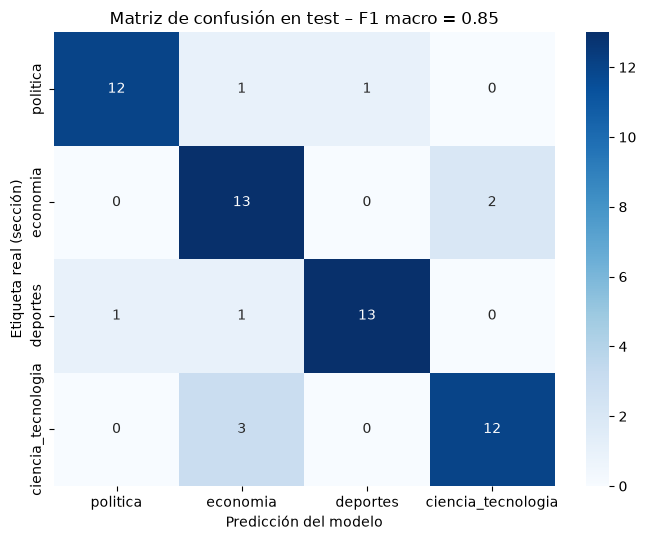

In [13]:
cm = confusion_matrix(y_true, y_pred, labels=CATEGORIAS)
plt.figure(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CATEGORIAS, yticklabels=CATEGORIAS)
plt.xlabel("Predicción del modelo"); plt.ylabel("Etiqueta real (sección)")
plt.title(f"Matriz de confusión en test – F1 macro = {f1_ft:.2f}")
plt.tight_layout(); plt.show()

In [14]:
f1_por_cat = pd.Series({c: reporte[c]["f1-score"] for c in CATEGORIAS}).sort_values(ascending=False)
print("F1 por categoría:\n" + f1_por_cat.round(3).to_string())
print(f"\nMejor: {f1_por_cat.index[0]} ({f1_por_cat.iloc[0]:.2f}) | Peor: {f1_por_cat.index[-1]} ({f1_por_cat.iloc[-1]:.2f})")

errores = test_df.assign(prediccion=y_pred).query("etiqueta != prediccion")
print(f"\nTitulares mal clasificados en test: {len(errores)}")
errores[["titular", "etiqueta", "prediccion"]]

F1 por categoría:
deportes              0.897
politica              0.889
ciencia_tecnologia    0.828
economia              0.788

Mejor: deportes (0.90) | Peor: economia (0.79)

Titulares mal clasificados en test: 9


,titular,etiqueta,prediccion
300,Ministro Guillermo Shinno presenta propuesta de nueva Ley Mape para formalización de mineros pequeños y artesanales,politica,economia
41,Informe Planeta Vivo 2026: la fauna silvestre cae 73% y América Latina es la región más golpeada (95 %),ciencia_tecnologia,economia
20,El tamaño medio de las poblaciones mundiales de vida silvestre disminuyó un 73% en 52 años,ciencia_tecnologia,economia
105,ASICS Golden Run 2026: así será el desvío vehicular y acceso peatonal el día de la competencia,deportes,economia
293,Premio Nobel de Economía: la macro es micro,economia,ciencia_tecnologia
286,IA y Sandbox regulatorio,economia,ciencia_tecnologia
369,Jaime Delgado: “Pienso que deberíamos mantenernos en los 20 puntos aprobados por Diputados”,politica,deportes
93,Millones de personas podrían tener que abandonar sus hogares por el cambio climático en el sudeste asiático,ciencia_tecnologia,economia
142,Annia Cillóniz en su llegada al Cusco como líder de su categoría: “Las mujeres estamos demostrando que se puede”,deportes,politica


### Reflexión por categoría

- **Mejor desempeño – `deportes` (F1 = 0.90):** su vocabulario es muy específico (nombres de clubes, torneos, deportistas), por lo que el modelo la distingue con facilidad. `politica` tiene un desempeño casi igual (F1 = 0.89), gracias a términos propios como "Congreso", "ministro" o "Fiscalía". Los pocos errores de deportes son titulares que no usan vocabulario deportivo: *"ASICS Golden Run 2026: así será el desvío vehicular y acceso peatonal"* habla de tránsito (predicho como economía), y la frase de Annia Cillóniz *"Las mujeres estamos demostrando que se puede"* suena a una declaración social o política (predicha como política).

- **Peor desempeño – `economia` (F1 = 0.79):** se confunde sobre todo con `ciencia_tecnologia`, en ambas direcciones:
  - **Ciencia → economía (4 de los 9 errores):** las noticias de medio ambiente, como *"la fauna silvestre cae 73%"* o *"el tamaño medio de las poblaciones ... disminuyó un 73% en 52 años"*, usan cifras, porcentajes y verbos como "cae" o "disminuyó", típicos de los titulares económicos. El modelo asocia ese lenguaje cuantitativo con economía.
  - **Economía → ciencia:** *"Premio Nobel de Economía: la macro es micro"* e *"IA y Sandbox regulatorio"* contienen palabras como "Nobel" e "IA", muy asociadas a ciencia y tecnología, aunque el tema sea económico.

  Además, *"Ministro Guillermo Shinno presenta propuesta de nueva Ley Mape para formalización de mineros"* (política) se predijo como economía, porque la minería es a la vez un tema político y económico. En resumen, los errores no son aleatorios: aparecen en titulares que **mezclan temas** o que usan el vocabulario típico de otra categoría.

## 6. Comparativa y decisión
Los tres enfoques se evalúan sobre **el mismo conjunto de test**, para que la comparación sea justa. También se mide la **latencia** (milisegundos por titular).

In [15]:
def medir_ms(funcion, textos):
    inicio = time.time()
    salida = funcion(textos)
    return salida, (time.time() - inicio) / len(textos) * 1000

# Zero-shot sobre el test completo
pred_zs, ms_zs = medir_ms(predecir_zero_shot, test_df["titular"])

# Transformer fine-tuned con pipeline (igual que en el dashboard)
clf_ft = pipeline("text-classification", model="modelo", tokenizer="modelo", device=DISPOSITIVO)
_, ms_ft = medir_ms(lambda t: clf_ft(list(t)), test_df["titular"])

# LLM: sus etiquetas del test ya existen; la latencia se registró al etiquetar
pred_llm = test_df["etiqueta_llm"].tolist()
ms_llm = np.nan
if os.path.exists("datos/llm_meta.json"):
    ms_llm = json.load(open("datos/llm_meta.json"))["seg_por_titular"] * 1000

comparativa = pd.DataFrame([
    {"Modelo": f"Zero-shot ({MODELO_ZS.split('/')[-1]})",
     "Accuracy": accuracy_score(y_true, pred_zs), "F1 macro": f1_score(y_true, pred_zs, average="macro"),
     "Latencia (ms/titular)": ms_zs, "Costo": "Gratis, CPU local; NLI × 4 hipótesis por titular"},
    {"Modelo": f"LLM débil ({MODELO_LLM})",
     "Accuracy": accuracy_score(y_true, pred_llm), "F1 macro": f1_score(y_true, pred_llm, average="macro", labels=CATEGORIAS),
     "Latencia (ms/titular)": ms_llm, "Costo": "API externa: cuota, límites y dependencia de internet"},
    {"Modelo": f"Fine-tuned ({MODELO_BASE})",
     "Accuracy": acc_ft, "F1 macro": f1_ft,
     "Latencia (ms/titular)": ms_ft, "Costo": "Entrenamiento único; inferencia local y rápida"},
])
comparativa.round({"Accuracy": 3, "F1 macro": 3, "Latencia (ms/titular)": 1})

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

,Modelo,Accuracy,F1 macro,Latencia (ms/titular),Costo
0,Zero-shot (bert-base-spanish-wwm-cased-xnli),0.593,0.558,166.3,"Gratis, CPU local; NLI × 4 hipótesis por titular"
1,LLM débil (gemini-flash-latest),0.966,0.966,1019.7,"API externa: cuota, límites y dependencia de internet"
2,Fine-tuned (distilbert-base-multilingual-cased),0.847,0.850,20.0,Entrenamiento único; inferencia local y rápida


### Justificación

| Modelo | F1 macro (test) | Latencia | Costo |
|---|---|---|---|
| Zero-shot | 0.558 | 166 ms | Gratis, local |
| LLM (Gemini) | **0.966** | ~1 020 ms | API externa con cuota |
| Fine-tuned (DistilBERT) | 0.850 | **20 ms** | Gratis, local |

**El LLM es el más preciso** (F1 de 0.966), algo esperable: es un modelo enorme, entrenado con muchísimo texto, y además lee el titular junto con la bajada. Sin embargo, **para un entorno real elegiría el Transformer fine-tuned**, porque ofrece el mejor equilibrio entre precisión, costo y latencia:

- **Precisión suficiente:** su F1 de 0.850 supera por casi 30 puntos al zero-shot (0.558). Pierde unos 12 puntos frente al LLM, pero eso es lógico, porque aprendió de las etiquetas del propio LLM con solo ~270 ejemplos de entrenamiento: su techo es la calidad de su "profesor".
- **Latencia:** clasifica un titular en **~20 ms**, unas **50 veces más rápido** que el LLM (~1 020 ms por titular, e incluso más si se envía cada titular por separado y no en lotes). Para un dashboard en vivo o miles de noticias diarias, esa diferencia es decisiva.
- **Costo y dependencia:** corre localmente, sin internet ni clave de API. El LLM depende de una cuota gratuita limitada: durante el proyecto hubo errores 429 y 503, y el modelo `gemini-2.5-flash` dejó de estar disponible (error 404), lo que obligó a cambiar el código.

**Conclusión:** el LLM fue clave como **etiquetador inicial**, porque ahorró el etiquetado manual de 388 noticias con un 100 % de acuerdo en la auditoría humana. Pero en producción conviene el modelo fine-tuned. Una mejora posible es un **esquema híbrido**: usar el fine-tuned para todos los titulares y consultar al LLM solo cuando la confianza del modelo sea baja (por ejemplo, menor a 0.5). Así se combina la rapidez del primero con la precisión del segundo, al mínimo costo.

## 7. Exportar métricas para el dashboard

In [16]:
metricas = {
    "n_noticias": int(len(df)),
    "f1_macro_test": round(float(f1_ft), 4),
    "accuracy_test": round(float(acc_ft), 4),
    "acuerdo_llm_humano": round(float(acuerdo_humano), 4),
    "f1_macro_zero_shot_40": round(float(f1_zs40), 4),
    "modelo_base": MODELO_BASE,
    "modelo_llm": MODELO_LLM,
    "fecha_entrenamiento": datetime.now().strftime("%Y-%m-%d"),
}
with open("modelo/metricas.json", "w", encoding="utf-8") as f:
    json.dump(metricas, f, indent=2, ensure_ascii=False)
metricas

{'n_noticias': 388,
 'f1_macro_test': 0.8502,
 'accuracy_test': 0.8475,
 'acuerdo_llm_humano': 1.0,
 'f1_macro_zero_shot_40': 0.5606,
 'modelo_base': 'distilbert-base-multilingual-cased',
 'modelo_llm': 'gemini-flash-latest',
 'fecha_entrenamiento': '2026-10-18'}